In [1]:
import torch
from torch import nn
from torchvision import datasets
from torchvision.transforms import v2
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
train_transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.RandomCrop(32, padding=4),
    v2.RandomHorizontalFlip(),
    v2.Normalize(
        mean=[0.4914, 0.4822, 0.4465],
        std=[0.2023, 0.1994, 0.2010],
    ),
])

eval_transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(
        mean=[0.4914, 0.4822, 0.4465],
        std=[0.2023, 0.1994, 0.2010],
    ),
])

In [3]:
train_aug_data = datasets.CIFAR10(
    root="data", train=True, download=True, transform=train_transform
)
train_eval_data = datasets.CIFAR10(
    root="data", train=True, download=True, transform=eval_transform
)
testing_data = datasets.CIFAR10(
    root="data", train=False, download=True, transform=eval_transform
)
indices = torch.randperm(
    len(train_aug_data), generator=torch.Generator().manual_seed(2)
).tolist()

train_set = Subset(train_aug_data, indices[:45_000])
val_set = Subset(train_eval_data, indices[45_000:])

In [4]:
train_dl = DataLoader(train_set, batch_size=64, shuffle=True)
val_dl = DataLoader(val_set, batch_size=64, shuffle=False)
test_dl = DataLoader(testing_data, batch_size=64, shuffle=False)

In [5]:
device = torch.accelerator.current_accelerator().type
print(device)

mps


In [6]:
images,labels = next(iter(test_dl))
print(images.shape)
print(labels.shape)

torch.Size([64, 3, 32, 32])
torch.Size([64])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.1770618..2.6952007].


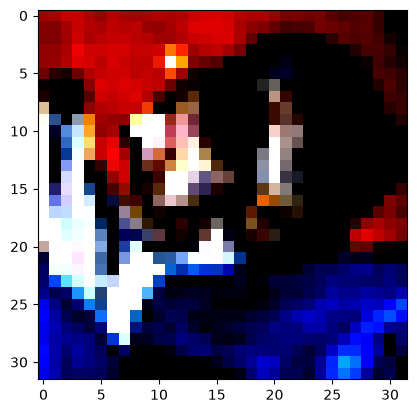

In [7]:
img = images[0]
plt.imshow(img.permute(1,2,0))
plt.show()

In [8]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64,64,3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(64*8*8, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128,10)
        )

    def forward(self, x):
        
        logits = self.linear_relu_stack(x)
        return logits

model = NeuralNetwork().to(device)
print(model)



NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0

In [9]:
loss_fn = nn.CrossEntropyLoss()
optimiser = torch.optim.Adam(model.parameters(), lr = 1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimiser, mode='min', factor=0.5, patience=3, min_lr = 1e-6)


In [10]:
def train(dataloader, model, loss_fn, optimiser):
    size = len(dataloader.dataset)
    model.train()
    for batch,(X,y) in enumerate(dataloader):
        X = X.to(device)
        y = y.to(device)
        pred = model(X)
        loss = loss_fn(pred, y)
        loss.backward()
        optimiser.step()
        optimiser.zero_grad()
        if (batch%100==0):
            loss, current = loss.item(), (batch+1)*len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")


In [11]:
def test(dataloader, model, loss_fn):
    model.eval()
    test_loss, correct = 0,0
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    with (torch.no_grad()):
        for X,y in dataloader:
            X,y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred,y).item()
            correct += (pred.argmax(dim=1)==y).type(torch.float).sum().item()
    test_loss /= num_batches
    correct /= size
    print(f"Accuracy: {100*correct}, Avg loss: {test_loss}")


In [12]:
epochs = 100
for t in range(epochs):
    print(f"epoch {t+1}")
    train(train_dl, model=model, loss_fn=loss_fn, optimiser=optimiser)
    test(val_dl, model = model, loss_fn=loss_fn)

epoch 1
loss: 2.349233  [   64/45000]
loss: 1.833384  [ 6464/45000]
loss: 1.473012  [12864/45000]
loss: 1.468993  [19264/45000]
loss: 1.520643  [25664/45000]
loss: 1.578001  [32064/45000]
loss: 1.553871  [38464/45000]
loss: 1.234522  [44864/45000]
Accuracy: 54.92, Avg loss: 1.2443819732605657
epoch 2
loss: 1.210036  [   64/45000]
loss: 1.141203  [ 6464/45000]
loss: 1.518478  [12864/45000]
loss: 1.031836  [19264/45000]
loss: 1.054232  [25664/45000]
loss: 1.022093  [32064/45000]
loss: 1.162487  [38464/45000]
loss: 1.055745  [44864/45000]
Accuracy: 63.6, Avg loss: 0.9872871026208129
epoch 3
loss: 1.083282  [   64/45000]
loss: 1.146357  [ 6464/45000]
loss: 1.159938  [12864/45000]
loss: 0.903716  [19264/45000]
loss: 0.895217  [25664/45000]
loss: 1.274896  [32064/45000]
loss: 1.016878  [38464/45000]
loss: 1.051058  [44864/45000]
Accuracy: 61.260000000000005, Avg loss: 1.0984091456932357
epoch 4
loss: 1.135805  [   64/45000]
loss: 0.769145  [ 6464/45000]
loss: 1.126362  [12864/45000]
loss: 1.

In [13]:
test(test_dl, model=model, loss_fn=loss_fn)

Accuracy: 85.48, Avg loss: 0.4673015358531551


In [14]:
CIFAR10_CLASSES = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

In [15]:
def generate_confusion_matrix(model, test_loader, device='cuda'):
    model.eval(),
    model.to(device),
    num_classes = 10
    conf_matrix = torch.zeros(num_classes, num_classes, dtype=torch.int64)
    with torch.no_grad():
        for images,labels in test_loader:
            images,labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            unique_indices = labels*num_classes + preds
            counts = torch.bincount(unique_indices, minlength=num_classes**2)
            conf_matrix+= counts.reshape(num_classes, num_classes).cpu()
    return conf_matrix.numpy()



def plot_confusion_matrix(cm, classes=CIFAR10_CLASSES, normalise = False):
    plt.figure(figsize=(5,4))
    if normalise:
        cm = cm.astype('float')/(cm.sum(axis=1)[:np.newaxis]+1e-8)
        fmt = '.2f'
        title = 'Normalised CIFAR10 Confusion matrix'
    else:
        fmt = 'd'
        title = 'CIFAR10 Confusion matrix'

    sns.heatmap(cm, annot=True, fmt = fmt, cmap = 'Blues', xticklabels=classes, yticklabels=classes)
    plt.title(title, fontsize=14, pad=12)
    plt.ylabel('True Label', fontsize=12)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.tight_layout()
    plt.show()

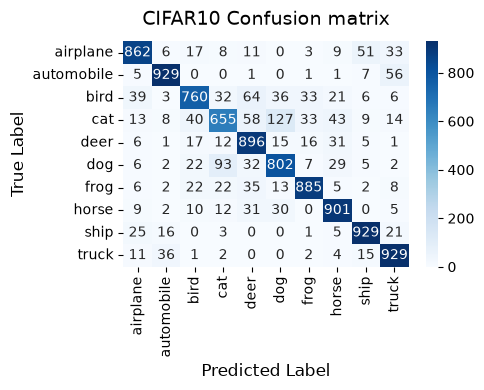

In [16]:
cm = generate_confusion_matrix(model, test_dl, device)
plot_confusion_matrix(cm, CIFAR10_CLASSES, normalise=False)

In [17]:
torch.save(model.state_dict(), "cifar10_cnn.pth")